In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchinfo
from torch.utils.data import DataLoader
from torchlake.common.constants import IMAGENET_MEAN, IMAGENET_STD
from torchlake.common.controller.trainer import ClassificationTrainer
from torchlake.common.controller.evaluator import ClassificationEvaluator
from torchlake.common.utils.convert import img_tensor_to_np
from torchlake.common.utils.platform import get_num_workers, get_file_size
from torchlake.image_classification.models.repvgg import RepVGG
from torchvision import transforms
from torchvision.datasets import EuroSAT
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Setting

In [26]:
SEED = 42

In [27]:
IMAGE_SIZE = 224
BATCH_SIZE = 64

In [28]:
artifact_path = Path("../../artifacts/repvgg")
artifact_path.mkdir(exist_ok=True)

data_path = Path("../../data/euroSAT")

In [29]:
DEVICE = torch.device("cuda:0")

# data

In [30]:
preprocess = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, saturation=0.2, contrast=0.2),
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [31]:
test_preprocess = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [32]:
train_dataset = EuroSAT(
    data_path.as_posix(),
    transform=preprocess,
    download=True,
)

In [33]:
NUM_CLASS = len(train_dataset.classes)

In [34]:
CLASS_NAMES = train_dataset.classes
CLASS_NAMES

['AnnualCrop',
 'Forest',
 'HerbaceousVegetation',
 'Highway',
 'Industrial',
 'Pasture',
 'PermanentCrop',
 'Residential',
 'River',
 'SeaLake']

In [35]:
len(train_dataset)

27000

River


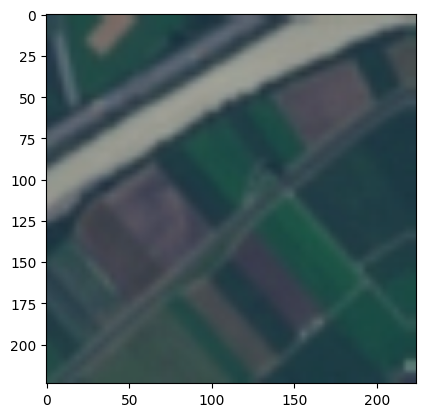

In [36]:
import random

demo_img, demo_label = train_dataset[random.randint(0, len(train_dataset))]
print(train_dataset.classes[demo_label])
plt.imshow((img_tensor_to_np(demo_img) * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1))

In [37]:
test_dataset = EuroSAT(
    data_path.as_posix(),
    transform=test_preprocess,
)

In [38]:
train_idx, test_idx = train_test_split(
    range(len(train_dataset)),
    test_size=0.2,
    stratify=train_dataset.targets,
    random_state=SEED,
)

In [39]:
train_dataset = Subset(train_dataset, train_idx)
test_dataset = Subset(test_dataset, test_idx)

In [40]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=True,
    num_workers=get_num_workers(),
)

# model

In [47]:
model = RepVGG(output_size=NUM_CLASS, key="a0").to(DEVICE)

In [48]:
torchinfo.summary(model)

Layer (type:depth-idx)                                            Param #
RepVGG                                                            --
├─RepVGGBlock: 1-1                                                --
│    └─Sequential: 2-1                                            --
│    │    └─InceptionModule: 3-1                                  1,632
│    │    └─ReLU: 3-2                                             --
├─Sequential: 1-2                                                 --
│    └─Sequential: 2-2                                            --
│    │    └─RepVGGBlock: 3-3                                      23,232
│    │    └─RepVGGBlock: 3-4                                      23,328
│    └─Sequential: 2-3                                            --
│    │    └─RepVGGBlock: 3-5                                      46,464
│    │    └─RepVGGBlock: 3-6                                      92,736
│    │    └─RepVGGBlock: 3-7                                      92,736
│    │

# training

In [49]:
epochs = 10
acc_iters = 64 // BATCH_SIZE

In [50]:
trainer = ClassificationTrainer(epochs, DEVICE, acc_iters)
trainer.recorder.increment_dataset_size(len(train_dataset))

In [51]:
criterion = trainer.get_criterion(NUM_CLASS)
optim = torch.optim.Adam(model.parameters())

In [52]:
training_loss = trainer.run(train_loader, model, optim, criterion)

Enable AMP: False
Training...


100%|██████████| 337/337 [01:31<00:00,  3.69it/s]


------------------------------------
Epoch 1
------------------------------------
total: 1.9095e-02 (0.00%)


100%|██████████| 337/337 [01:20<00:00,  4.21it/s]


------------------------------------
Epoch 2
------------------------------------
total: 1.1326e-02 (-41.00%)


100%|██████████| 337/337 [01:21<00:00,  4.13it/s]


... (11 outputs left out)

100%|██████████| 337/337 [01:11<00:00,  4.70it/s]


------------------------------------
Epoch 9
------------------------------------
total: 2.9282e-03 (-11.00%)


100%|██████████| 337/337 [01:11<00:00,  4.71it/s]

------------------------------------
Epoch 10
------------------------------------
total: 2.6351e-03 (-10.00%)


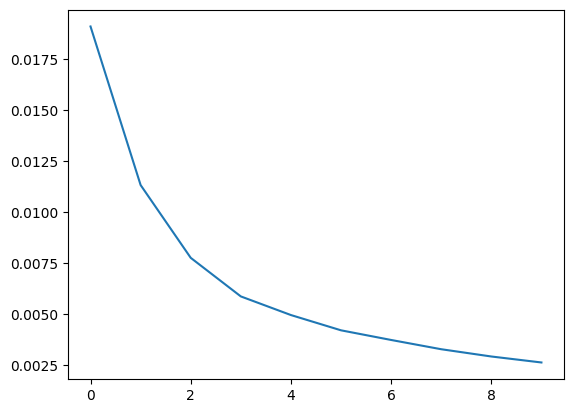

In [53]:
plt.plot(training_loss)

# inference

In [54]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    pin_memory=True,
    num_workers=get_num_workers(),
)

In [74]:
evaluator = ClassificationEvaluator(NUM_CLASS, DEVICE)

In [75]:
confusion_matrix = evaluator.run(test_loader, model)

100%|██████████| 85/85 [00:11<00:00,  7.30it/s]


In [76]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(range(NUM_CLASS), per_class_acc)

0         : 0.97
1         : 0.9833333333333333
2         : 0.9516666666666667
3         : 0.966
4         : 0.978
5         : 0.9
6         : 0.82
7         : 0.8983333333333333
8         : 0.932
9         : 0.995


In [77]:
per_class_acc.mean()

np.float64(0.9394333333333332)

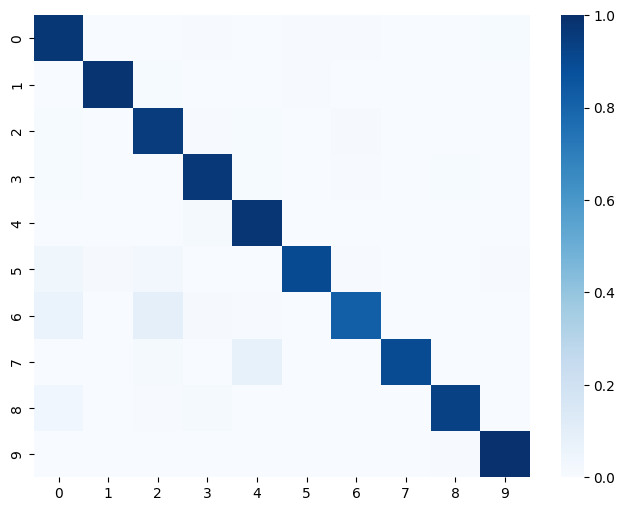

In [59]:
evaluator.plot_confusion_matrix(
    confusion_matrix,
    range(NUM_CLASS),
    "Blues",
    annot=False,
    figsize=(8, 6),
)

In [60]:
model_path = artifact_path / f"repvgg.{model.key}.pth"

In [61]:
torch.save(model.state_dict(), model_path)

In [62]:
get_file_size(model_path)

'30.12MiB'

In [63]:
model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>

## reparametrize

In [64]:
reparametrized_model = model.reparameterize()

In [78]:
evaluator = ClassificationEvaluator(NUM_CLASS, DEVICE)

In [79]:
confusion_matrix = evaluator.run(test_loader, reparametrized_model)

100%|██████████| 85/85 [00:12<00:00,  6.69it/s]


In [80]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(range(NUM_CLASS), per_class_acc)

0         : 0.97
1         : 0.9833333333333333
2         : 0.9516666666666667
3         : 0.966
4         : 0.978
5         : 0.9
6         : 0.82
7         : 0.8983333333333333
8         : 0.932
9         : 0.995


In [68]:
per_class_acc.mean()

np.float64(0.9394333333333332)

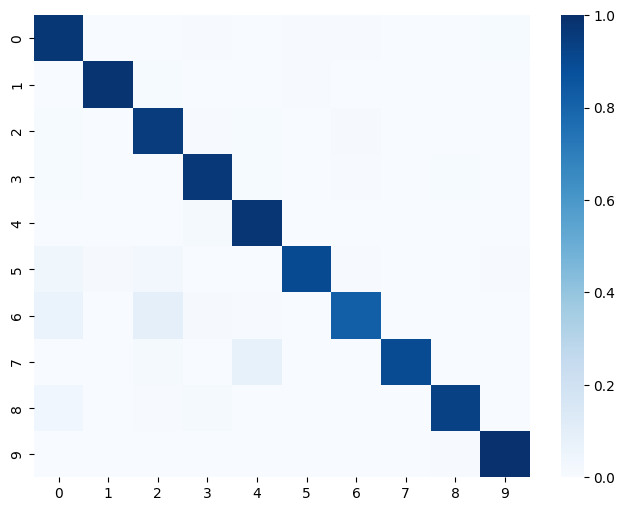

In [69]:
evaluator.plot_confusion_matrix(
    confusion_matrix,
    range(NUM_CLASS),
    "Blues",
    annot=False,
    figsize=(8, 6),
)

In [70]:
model_path = artifact_path / f"repvgg.{model.key}.reparametrized.pth"

In [71]:
torch.save(reparametrized_model.state_dict(), model_path)

In [72]:
get_file_size(model_path)

'26.88MiB'

In [73]:
reparametrized_model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>